In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

In [2]:
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# Normalize
x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.

# Add noise
noise_factor = 0.5
x_train_noisy = x_train + noise_factor * np.random.normal(size=x_train.shape)
x_test_noisy = x_test + noise_factor * np.random.normal(size=x_test.shape)

x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


**Denoising Autoencoder Model**

In [3]:
input_img = layers.Input(shape=(28, 28, 1))

# Encoder
x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2,2), padding='same')(x)

# Decoder
x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2,2))(x)
decoded = layers.Conv2D(1, (3,3), activation='sigmoid', padding='same')(x)

autoencoder = models.Model(input_img, decoded)
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

**Prepare Data Shape**

In [4]:
x_train_noisy = np.reshape(x_train_noisy, (-1,28,28,1))
x_test_noisy = np.reshape(x_test_noisy, (-1,28,28,1))

x_train = np.reshape(x_train, (-1,28,28,1))
x_test = np.reshape(x_test, (-1,28,28,1))

**Train Model**

In [5]:
history = autoencoder.fit(
    x_train_noisy, x_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_test_noisy, x_test)
)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 87s 182ms/step - loss: 0.1609 - val_loss: 0.1106
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 83s 177ms/step - loss: 0.1095 - val_loss: 0.1071
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 84s 178ms/step - loss: 0.1073 - val_loss: 0.1055
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 142s 179ms/step - loss: 0.1058 - val_loss: 0.1044
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 141s 177ms/step - loss: 0.1047 - val_loss: 0.1032


**Plot Loss Graph**

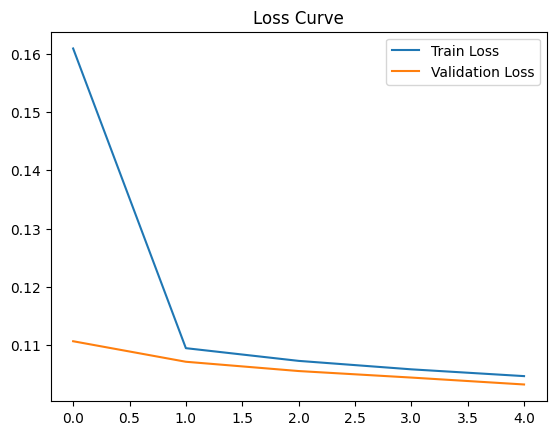

In [6]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Loss Curve")
plt.show()

**Show Results (Before vs After)**

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step


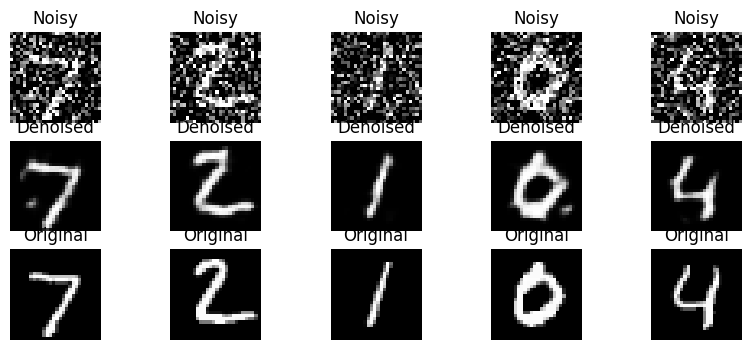

In [7]:
decoded_imgs = autoencoder.predict(x_test_noisy)

n = 5
plt.figure(figsize=(10,4))

for i in range(n):
    # Noisy
    ax = plt.subplot(3, n, i+1)
    plt.imshow(x_test_noisy[i].reshape(28,28), cmap='gray')
    plt.title("Noisy")
    plt.axis("off")

    # Clean
    ax = plt.subplot(3, n, i+n+1)
    plt.imshow(decoded_imgs[i].reshape(28,28), cmap='gray')
    plt.title("Denoised")
    plt.axis("off")

    # Original
    ax = plt.subplot(3, n, i+2*n+1)
    plt.imshow(x_test[i].reshape(28,28), cmap='gray')
    plt.title("Original")
    plt.axis("off")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


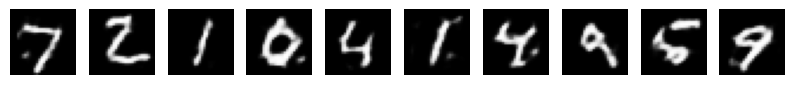

In [8]:
encoded_imgs = autoencoder.predict(x_test_noisy[:10])

plt.figure(figsize=(10,2))
for i in range(10):
    plt.subplot(1,10,i+1)
    plt.imshow(encoded_imgs[i].reshape(28,28), cmap='gray')
    plt.axis('off')
plt.show()

**VAE**

In [9]:
latent_dim = 2

inputs = layers.Input(shape=(28,28,1))
x = layers.Flatten()(inputs)
x = layers.Dense(128, activation='relu')(x)

z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)

In [11]:
def sampling(args):
    z_mean, z_log_var = args
    epsilon = tf.random.normal(shape=(tf.shape(z_mean)[0], latent_dim))
    return z_mean + tf.exp(0.5*z_log_var)*epsilon

z = layers.Lambda(sampling)([z_mean, z_log_var])
decoder = models.Sequential([
    layers.Dense(128, activation='relu'),
    layers.Dense(784, activation='sigmoid'),
    layers.Reshape((28,28,1))
])

outputs = decoder(z)
vae = models.Model(inputs, outputs)
vae.compile(optimizer='adam', loss='binary_crossentropy')

vae.fit(x_train, x_train, epochs=3, batch_size=128)

Epoch 1/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 0.2568
Epoch 2/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2180
Epoch 3/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2086


**GAN**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


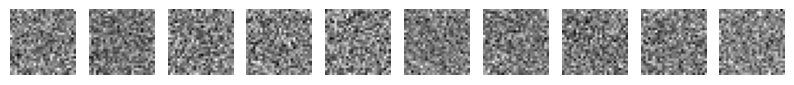

In [12]:
generator = models.Sequential([
    layers.Dense(128, activation='relu', input_dim=100),
    layers.Dense(784, activation='sigmoid'),
    layers.Reshape((28,28))
])

noise = np.random.normal(0,1,(10,100))
generated_images = generator.predict(noise)

plt.figure(figsize=(10,2))
for i in range(10):
    plt.subplot(1,10,i+1)
    plt.imshow(generated_images[i], cmap='gray')
    plt.axis('off')
plt.show()



In [13]:
def generate_caption():
    captions = [
        "A handwritten digit",
        "A grayscale image of number",
        "Digit from MNIST dataset"
    ]
    return np.random.choice(captions)

for i in range(3):
    print("Caption:", generate_caption())

Caption: A handwritten digit
Caption: Digit from MNIST dataset
Caption: Digit from MNIST dataset


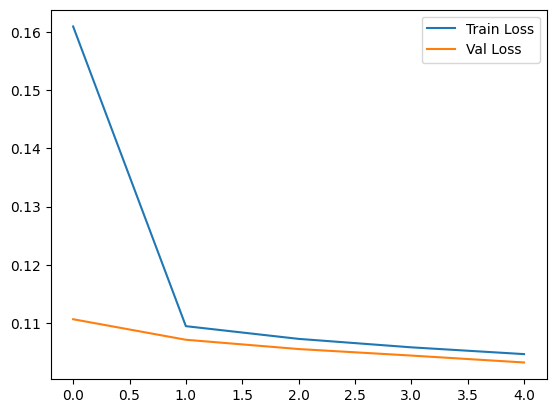

In [14]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.show()